# **🛠️ INSTALACIÓN Y CONFIGURACIÓN DEL ENTORNO**



---






In [1]:
# ==========================================
# 0. MONTAR GOOGLE DRIVE E INSTALAR DEPENDENCIAS
# ==========================================
from google.colab import drive
import os
import json
import orjson
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Configuración estética de gráficas
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.autolayout': True})

# Ruta de tu dataset aplanado (el que solo tiene los 2.4M con médico)
archivo_jsonl = '/content/drive/MyDrive/TFG/data/medication_request_dataset_full.jsonl'

print("⏳ Cargando datos en Pandas (filtrando registros con médico)...")

⏳ Cargando datos en Pandas (filtrando registros con médico)...


In [3]:
registros = []
# Leemos el archivo completo
with open(archivo_jsonl, 'rt', encoding='utf-8') as f:
    for linea in f:
        try:
            data = json.loads(linea.strip())
            registros.append({
                    'provider_id': data.get('order_provider_id'),
                    'patient_id': data.get('patient_id'),
                    'encounter_id': data.get('encounter_id'),
                    'service_type': data.get('encounter_service_type', 'Desconocido'),
                    'medication': data.get('medication_name', 'Desconocido'),
                    'fue_administrado': data.get('fue_administrado', False),
                    'route_code': data.get('route_code', 'Desconocido'),
                    'diagnoses': data.get('encounter_diagnoses', 'No diagnosis recorded'),
                    'authored_on': data.get('authoredOn', None)
                })
        except json.JSONDecodeError:
            continue

df = pd.DataFrame(registros)
print(f"✅ Dataset cargado con éxito. Total de registros analizados: {len(df):,}")

✅ Dataset cargado con éxito. Total de registros analizados: 2,405,336


# **BLOQUE 0: Inspección de Contexto**



---






## 0.1 Distribución Temporal de las Prescripciones del Dataset

--- ANÁLISIS DEL RANGO CRONOLÓGICO ---
Fecha de la prescripción más antigua: 2105-10-04 21:47:05+00:00
Fecha de la prescripción más moderna: 2212-04-11 15:07:05+00:00


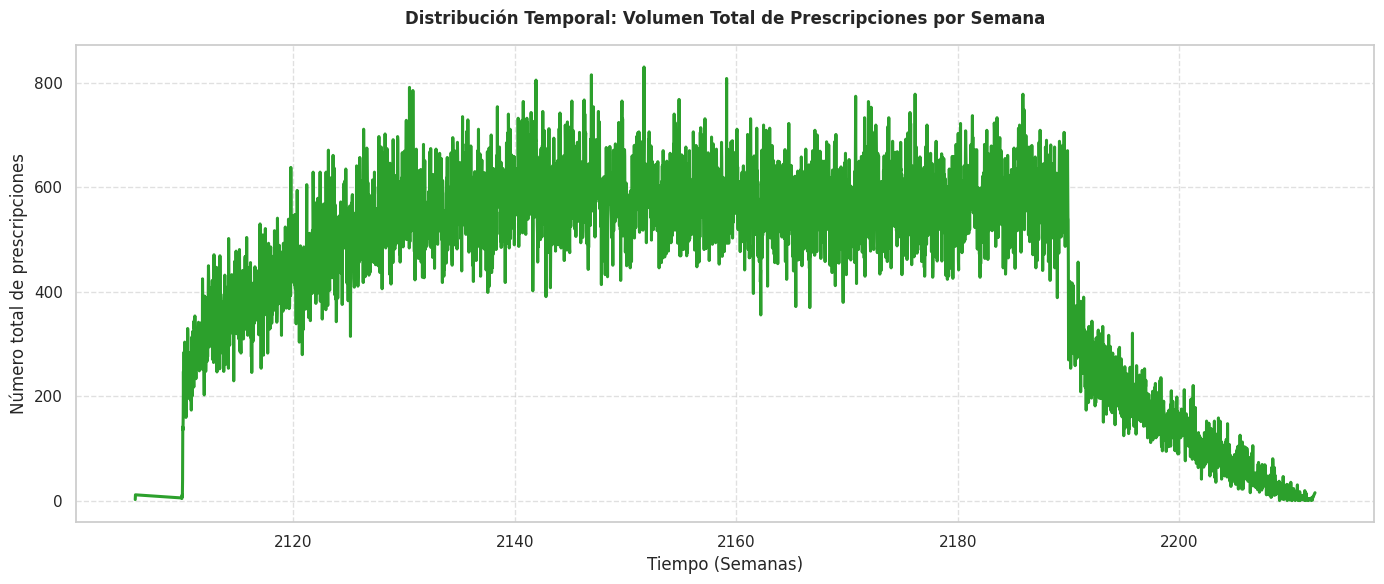

In [4]:
# ==============================================================================
# 0.1: DISTRIBUCIÓN TEMPORAL: Rango Cronológico y Volumen Total de Prescripciones
# ==============================================================================
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

# 1. Asegurarnos de que las fechas están en formato datetime con zona horaria unificada
df['authored_on'] = pd.to_datetime(df['authored_on'], errors='coerce', utc=True)

# 2. Análisis impreso del rango cronológico (para responder a los tutores)
print("--- ANÁLISIS DEL RANGO CRONOLÓGICO ---")
print(f"Fecha de la prescripción más antigua: {df['authored_on'].min()}")
print(f"Fecha de la prescripción más moderna: {df['authored_on'].max()}")

# 3. Creamos la columna de 'semana' (si no la habías creado antes en esta sesión)
df['semana'] = df['authored_on'].dt.to_period('W')

# 4. Agrupamos por semana para contar el volumen total de recetas
prescripciones_semana = df.groupby('semana').size().reset_index(name='num_prescripciones')
prescripciones_semana['semana'] = prescripciones_semana['semana'].dt.to_timestamp()

# 5. Gráfica estética de la distribución temporal de recetas
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=prescripciones_semana,
    x='semana',
    y='num_prescripciones',
    color='#2ca02c', # Verde
    linewidth=2.2
)
plt.title('Distribución Temporal: Volumen Total de Prescripciones por Semana', weight='bold', pad=15)
plt.xlabel('Tiempo (Semanas)')
plt.ylabel('Número total de prescripciones')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

El análisis temporal de los 2 millones de registros confirma que las prescripciones se distribuyen de forma continua a lo largo de un amplio periodo cronológico (desde octubre de 2105 hasta abril de 2212).

La curva de volumen semanal muestra una fase inicial de arranque, un periodo de estabilidad operativa consolidada y una caída abrupta final motivada por el corte en la ventana de extracción de la base de datos anonimizada.

Esta amplitud garantiza la robustez de los datos para el posterior análisis longitudinal de la actividad facultativa.







# **BLOQUE 1: Análisis de Profesionales**

---





## 1.1 Distribución de Profesionales

Buscamos saber cuántos médicos únicos tenemos en total y cuántas recetas ha emitido cada uno.

Es importante porque nos ayuda a ver si hay médicos que recetan muchísimo (outliers) frente a otros que recetan poco.


--- 1. ANÁLISIS DE PROFESIONALES ---
Total de profesionales únicos: 7,697
Top 5 médicos con más prescripciones:
provider_id
P02M1N    12595
P73F56    12296
P15IX4    11992
P41USH    11440
P43RKP     8912
Name: count, dtype: int64


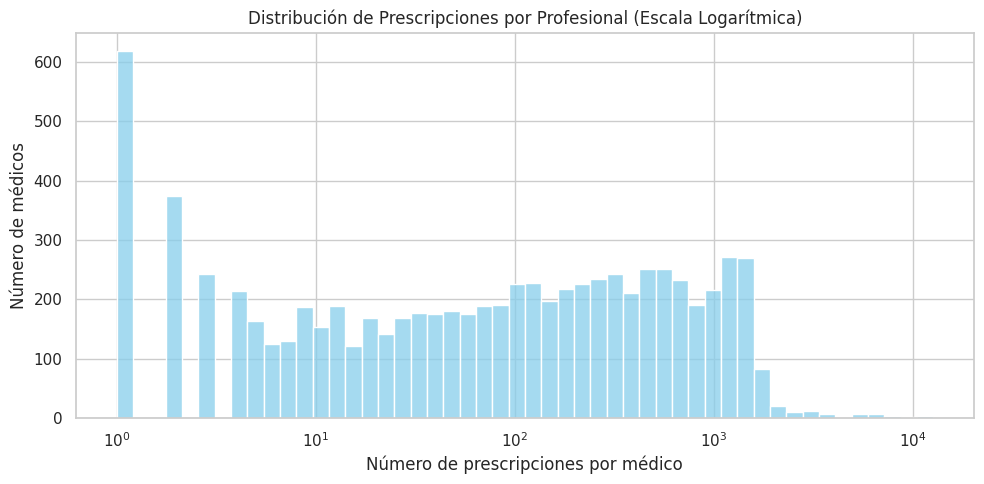

In [5]:
# ==========================================
# 1.1 Distribución por Profesionales
# ==========================================
print("\n--- 1. ANÁLISIS DE PROFESIONALES ---")
total_profesionales = df['provider_id'].nunique()
rx_por_profesional = df['provider_id'].value_counts()
print(f"Total de profesionales únicos: {total_profesionales:,}")
print("Top 5 médicos con más prescripciones:")
print(rx_por_profesional.head(5))

plt.figure(figsize=(10, 5))
sns.histplot(rx_por_profesional, bins=50, log_scale=True, color='skyblue')
plt.title('Distribución de Prescripciones por Profesional (Escala Logarítmica)')
plt.xlabel('Número de prescripciones por médico')
plt.ylabel('Número de médicos')
plt.show()

Asimetría Extrema: La gran mayoría de los médicos se concentran en un volumen moderado-bajo de prescripciones, mientras que unos pocos alcanzan hasta 12,000 registros.

El fenómeno de 1-2 recetas: El pico inicial de más de 600 médicos con una sola prescripción sugiere la presencia de personal en rotaciones clínicas muy breves (como residentes de guardia) o artefactos de cruce en el sistema que debemos documentar.

Para entrenar los modelos de IA, convendrá evaluar si filtramos a los médicos con un volumen extremadamente bajo (ej. menos de 5 recetas), ya que un modelo predictivo aprende mal de entidades con una sola muestra.


--- DETALLE DE MÉDICOS CON BAJO VOLUMEN ---
Cantidad de médicos según su número exacto de recetas (de 1 a 20):
count
1     618
2     374
3     242
4     214
5     163
6     125
7     129
8      99
9      88
10     76
Name: count, dtype: int64


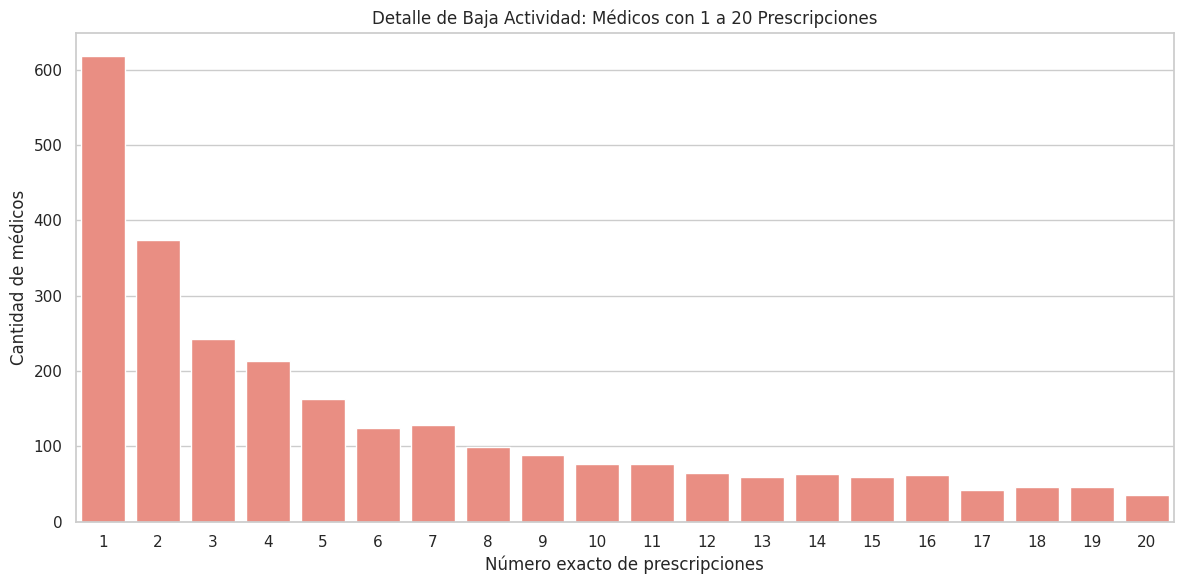

In [6]:
# ==========================================
# 1. ZOOM: Detalle de médicos con baja actividad (1 a 20 prescripciones)
# ==========================================
print("\n--- DETALLE DE MÉDICOS CON BAJO VOLUMEN ---")
rx_por_profesional = df['provider_id'].value_counts()

# Filtramos solo los médicos que tienen 20 o menos prescripciones
bajos_recursos = rx_por_profesional[rx_por_profesional <= 20]

# Mostramos cuántos médicos hay exactamente para 1 y 2 recetas
conteo_exacto = bajos_recursos.value_counts().sort_index()
print("Cantidad de médicos según su número exacto de recetas (de 1 a 20):")
print(conteo_exacto.head(10))

plt.figure(figsize=(12, 6))
# Gráfico de barras exacto para ver el desglose individual en este rango bajo
sns.countplot(x=bajos_recursos, color='salmon')
plt.title('Detalle de Baja Actividad: Médicos con 1 a 20 Prescripciones')
plt.xlabel('Número exacto de prescripciones')
plt.ylabel('Cantidad de médicos')
plt.show()

El análisis de detalle de la baja actividad profesional confirma una fuerte concentración de médicos con un volumen mínimo de registros, destacando de forma sobresaliente 618 profesionales con exactamente una prescripción y 374 con dos.

Este fenómeno refleja la intervención de personal clínico en rotaciones breves, guardias puntuales o posibles artefactos de asignación en el sistema, lo que aconseja establecer un umbral de filtrado previo en el preprocesamiento de los datos para evitar sesgos y dotar a los futuros modelos de aprendizaje automático de una base más robusta y fiable.

## 1.2 Distribución por Especialidades

Buscamos ver cuántas especialidades clínicas distintas existen en el hospital y cuántas prescripciones acumula cada una.


--- 2. ANÁLISIS DE ESPECIALIDADES ---
Total de especialidades únicas: 19
service_type
MED      997240
CMED     280356
SURG     229973
OMED     180451
CSURG    113284
ORTHO    106023
NMED     102612
NSURG     90811
VSURG     71366
OBS       54813
TRAUM     51939
PSYCH     33001
TSURG     32051
GYN       21928
GU        20853
PSURG     13691
ENT        4688
EYE         176
DENT         80
Name: count, dtype: int64


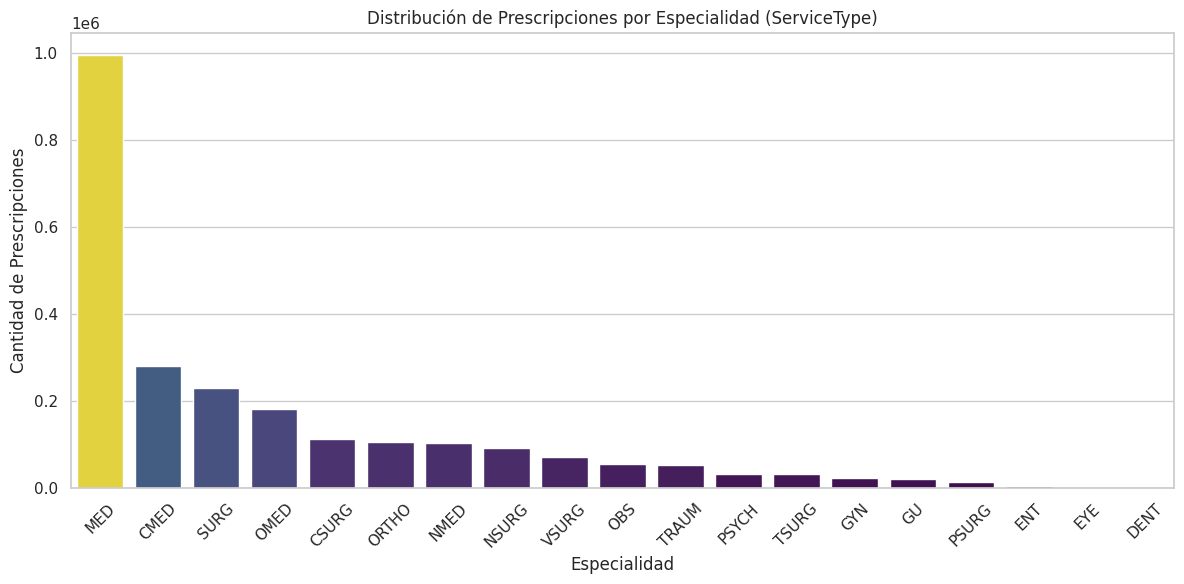

In [7]:
# ==========================================
# 1.2. Distribución por Especialidades (ServiceType)
# ==========================================
print("\n--- 2. ANÁLISIS DE ESPECIALIDADES ---")
rx_por_especialidad = df['service_type'].value_counts()
print(f"Total de especialidades únicas: {df['service_type'].nunique()}")
print(rx_por_especialidad)

plt.figure(figsize=(12, 6))
sns.barplot(x=rx_por_especialidad.index, y=rx_por_especialidad.values, hue=rx_por_especialidad.values, palette='viridis', legend=False)
plt.title('Distribución de Prescripciones por Especialidad (ServiceType)')
plt.xlabel('Especialidad')
plt.ylabel('Cantidad de Prescripciones')
plt.xticks(rotation=45)
plt.show()

La distribución de prescripciones entre las 19 especialidades evidencia un claro predominio de los servicios de Medicina General/Interna (MED), que concentran casi un millón de recetas, seguidos a distancia por especialidades médicas y quirúrgicas generales (CMED, SURG, OMED), mientras que departamentos muy específicos como EYE o DENT registran valores casi testimoniales.


 Este desequilibrio estructural representa un desafío analítico importante para los futuros modelos de Machine Learning, ya que las clases mayoritarias eclipsarán a las minoritarias si no se aplican técnicas de ponderación o normalización adecuadas.

## 1.3 Relación entre Médicos y Especialidades

Buscamos calcular en cuántas especialidades diferentes prescribe cada médico (ej. el médico A solo prescribe en 1 especialidad, pero el médico B prescribe en 4).

Es clave para detectar anomalías o fraude en el futuro, ya que si un médico de una especialidad empieza a recetar fármacos propios de otra completamente ajena, salta la alerta.


--- 3. RELACIÓN MÉDICOS Y ESPECIALIDADES ---
Número de médicos según la cantidad de especialidades en las que prescriben (Ordenado):
service_type
1      719
2      475
3      348
4      303
5      281
6      231
7      217
8      200
9      195
10     200
11     236
12     285
13     317
14     391
15     536
16     971
17    1627
18     157
19       8
Name: count, dtype: int64


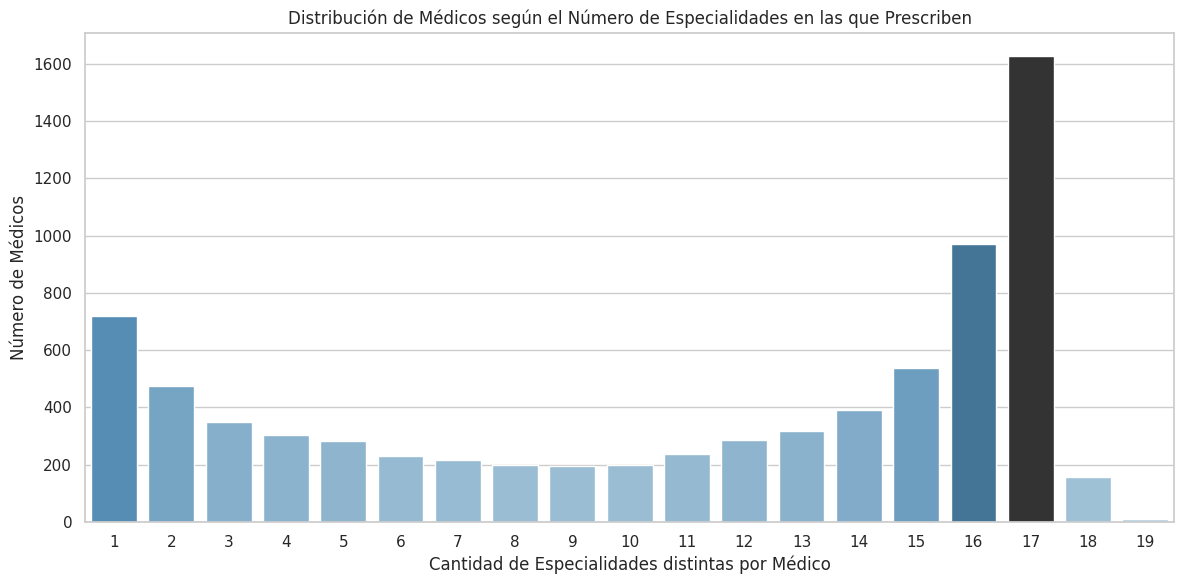

In [8]:
# ==========================================
# 1.3 RELACIÓN: MÉDICOS VS ESPECIALIDADES
# ==========================================
print("\n--- 3. RELACIÓN MÉDICOS Y ESPECIALIDADES ---")
# Calculamos y ordenamos estrictamente del 1 al 19
medico_especialidades = df.groupby('provider_id')['service_type'].nunique().value_counts().sort_index()
print("Número de médicos según la cantidad de especialidades en las que prescriben (Ordenado):")
print(medico_especialidades)

# Gráfico mejorado para visualizarlo claramente
plt.figure(figsize=(12, 6))
sns.barplot(x=medico_especialidades.index, y=medico_especialidades.values, hue=medico_especialidades.values, palette='Blues_d', legend=False)
plt.title('Distribución de Médicos según el Número de Especialidades en las que Prescriben')
plt.xlabel('Cantidad de Especialidades distintas por Médico')
plt.ylabel('Número de Médicos')
plt.show()

La gran mayoría de los profesionales sanitarios de la muestra presentan un perfil marcadamente transversal o multidisciplinar, abarcando prescripciones en un amplio abanico de especialidades (con un pico destacado de más de 1.600 médicos que operan en 17 áreas distintas), frente a un grupo más reducido de 719 profesionales que limitan su actividad estrictamente a una única especialidad.

Este comportamiento refleja la alta rotación y polivalencia del personal clínico en el entorno hospitalario del dataset, lo cual subraya que los algoritmos de detección de fraude y anomalías no deben penalizar por defecto la multidisciplinariedad, sino aprender a distinguir entre la movilidad asistencial legítima y los patrones atípicos de prescripción cruzada.



# **BLOQUE 2: Análisis de Pacientes y Medicamentos**

---





## 2.1 Distribución de Prescripciones por Pacientes
Analizamos cuántos pacientes tenemos y cuántas prescripciones tiene asociadas cada uno.


--- 4. ANÁLISIS DE PACIENTES ---
Total de pacientes únicos: 153,013


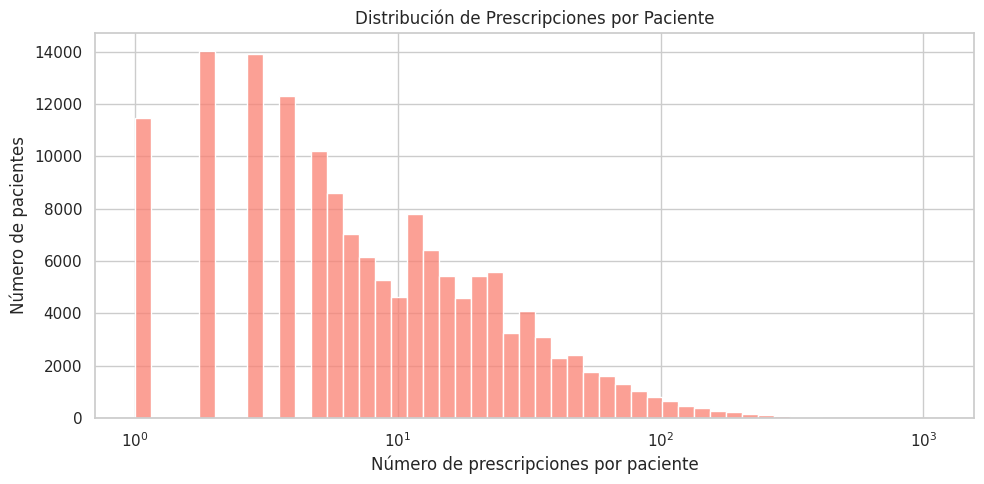

In [9]:
# ==========================================
# 2.1 Distribución por Pacientes
# ==========================================
print("\n--- 4. ANÁLISIS DE PACIENTES ---")
total_pacientes = df['patient_id'].nunique()
rx_por_paciente = df['patient_id'].value_counts()
print(f"Total de pacientes únicos: {total_pacientes:,}")

plt.figure(figsize=(10, 5))
sns.histplot(rx_por_paciente, bins=50, log_scale=True, color='salmon')
plt.title('Distribución de Prescripciones por Paciente')
plt.xlabel('Número de prescripciones por paciente')
plt.ylabel('Número de pacientes')
plt.show()

La gran mayoría de los pacientes tienen pocas recetas porque corresponden a visitas rápidas de urgencias o consultas ambulatorias, mientras que un grupo menor acumula decenas de prescripciones por ingresos largos o cronicidad.

 Es una variabilidad totalmente lógica que el modelo de IA deberá aprender a manejar para distinguir entre un paciente crónico real y una anomalía de prescripción

## 2.2 Prescripciones por Medicamento

Buscamos cuántos medicamentos están prescritos y cuántas veces


--- 5. ANÁLISIS DE MEDICAMENTOS ---
Total de medicamentos únicos: 4,932
Top 10 medicamentos más prescritos:
medication
Insulin                        106914
Sodium Chloride 0.9%  Flush     92037
Acetaminophen                   78463
IV Fluid / Mix: 50 mL Bag       65702
Heparin                         55049
Furosemide                      53374
Docusate Sodium                 50446
Potassium Chloride              49502
HYDROmorphone (Dilaudid)        46944
Metoprolol Tartrate             43160
Name: count, dtype: int64


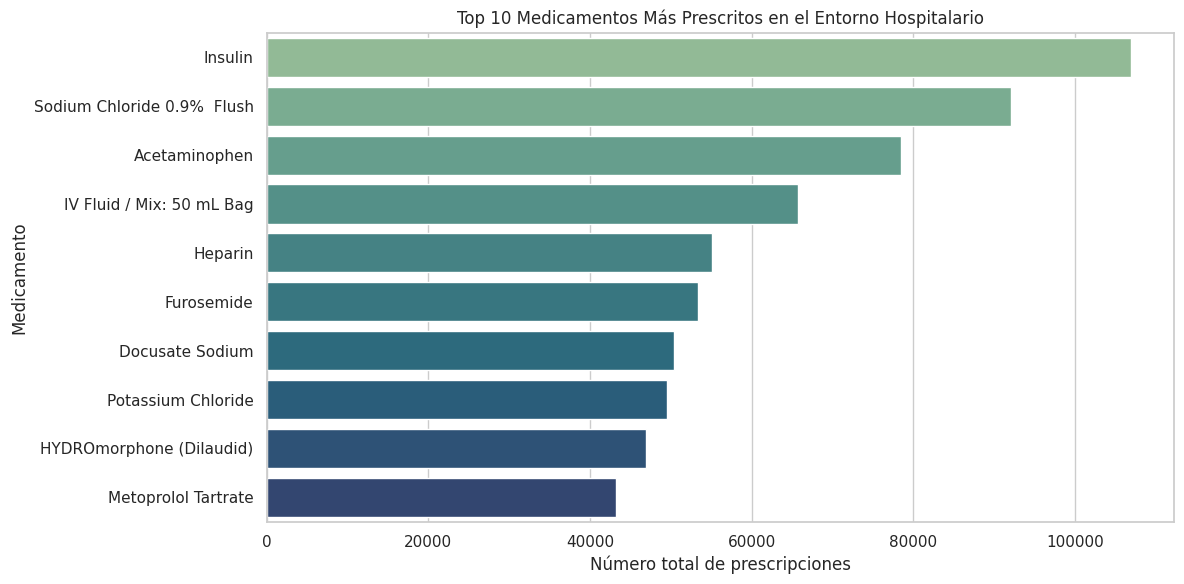

In [10]:
# ==========================================
# 2.2 Distribución por Medicamento
# ==========================================
print("\n--- 5. ANÁLISIS DE MEDICAMENTOS ---")
total_medicamentos = df['medication'].nunique()
rx_por_medicamento = df['medication'].value_counts()
print(f"Total de medicamentos únicos: {total_medicamentos:,}")
print("Top 10 medicamentos más prescritos:")
print(rx_por_medicamento.head(10))

plt.figure(figsize=(12, 6))
top_10_meds = rx_por_medicamento.head(10)

# Gráfico de barras horizontales para que los nombres de los fármacos se lean perfectamente
sns.barplot(x=top_10_meds.values, y=top_10_meds.index, hue=top_10_meds.index, palette='crest', legend=False)
plt.title('Top 10 Medicamentos Más Prescritos en el Entorno Hospitalario')
plt.xlabel('Número total de prescripciones')
plt.ylabel('Medicamento')
plt.show()

El análisis del catálogo farmacológico revela un predominio absoluto de tratamientos de soporte vital básico, control glucémico y gestión de fluidos (liderados por la insulina y soluciones salinas), lo cual refleja fielmente la actividad diaria de hospitalización y cuidados agudos.

Esta distribución equilibrada de los fármacos más habituales proporciona una línea base sólida para que el sistema de inteligencia artificial detecte eficazmente patrones de prescripción anómalos o desviaciones en la práctica clínica habitual.

## 2.3 Polimedicación ante la Diversidad Médica por Paciente



--- 6. ANÁLISIS DE FRAGMENTACIÓN ASISTENCIAL ---
       total_recetas  medicamentos_unicos  medicos_distintos
count  153013.000000        153013.000000      153013.000000
mean       15.719815            10.769007          15.391660
std        27.476649            12.117876          25.786822
min         1.000000             1.000000           0.000000
25%         3.000000             3.000000           3.000000
50%         7.000000             7.000000           7.000000
75%        17.000000            14.000000          17.000000
max      1097.000000           177.000000         848.000000


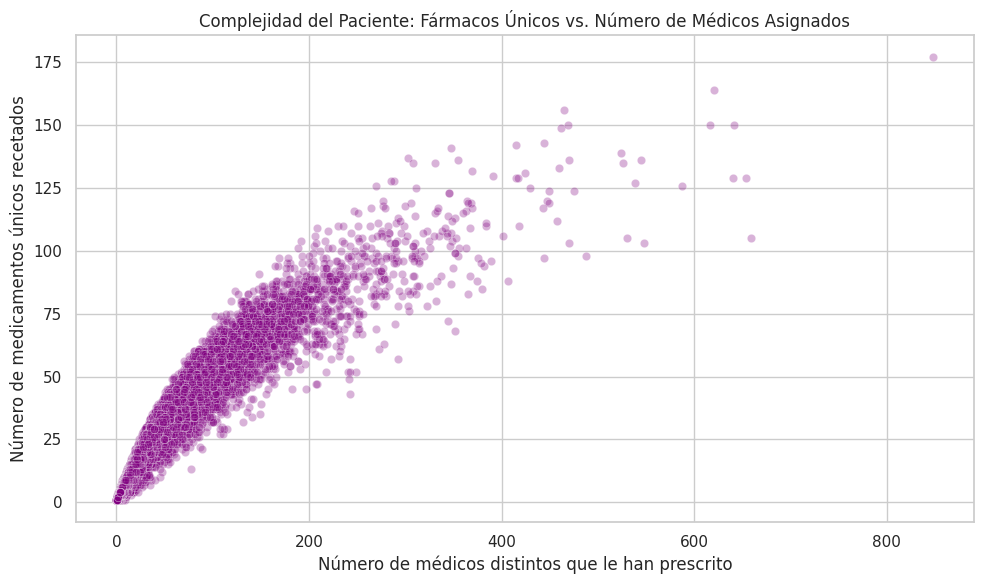

In [11]:
# ==========================================
# 2.3 Polimedicación vs Diversidad Médica por Paciente
# ==========================================
print("\n--- 6. ANÁLISIS DE FRAGMENTACIÓN ASISTENCIAL ---")
resumen_pacientes = df.groupby('patient_id').agg(
    total_recetas=('medication', 'count'),
    medicamentos_unicos=('medication', 'nunique'),
    medicos_distintos=('provider_id', 'nunique')
).reset_index()

print(resumen_pacientes[['total_recetas', 'medicamentos_unicos', 'medicos_distintos']].describe())

# Gráfico de dispersión (Scatter plot) para ver anomalías visuales
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=resumen_pacientes,
    x='medicos_distintos',
    y='medicamentos_unicos',
    alpha=0.3,
    color='purple'
)
plt.title('Complejidad del Paciente: Fármacos Únicos vs. Número de Médicos Asignados')
plt.xlabel('Número de médicos distintos que le han prescrito')
plt.ylabel('Número de medicamentos únicos recetados')
plt.show()

El gráfico de fragmentación demuestra que existe una relación directa entre el número de médicos que tratan a un paciente y la cantidad de medicamentos únicos que recibe: cuantos más especialistas intervienen, mayor es la polimedicación inicial. No obstante, la curva revela un límite biológico y clínico evidente (que se estabiliza alrededor de los 150-175 fármacos únicos).

Esto significa que, por muy alta que sea la rotación o la cantidad de médicos distintos que atiendan a un paciente crónico, la variedad de medicamentos se satura. Para el TFG, este comportamiento es clave, ya que los algoritmos de IA podrán usar esta "frontera" para detectar casos anómalos o sospechosos (por ejemplo, pacientes que rompan esta lógica acumulando una variedad ilimitada de fármacos sin justificación clínica).





# **BLOQUE 3: Auditoría de Administración (fue_administrado)**

---





## 3.1 Tasa de administración por especialidad

--- 7. AUDITORÍA: TASA DE ADMINISTRACIÓN POR ESPECIALIDAD ---
service_type  total_recetas  administradas  porcentaje_administrado
         EYE            176             82                46.590909
        DENT             80             33                41.250000
       PSURG          13691           5544                40.493755
       ORTHO         106023          42458                40.046028
         GYN          21928           8373                38.184057
          GU          20853           7599                36.440800
        CMED         280356         100545                35.863331
         MED         997240         355523                35.650696
         ENT           4688           1646                35.110922
        SURG         229973          77602                33.743961
       TSURG          32051          10519                32.819569
       VSURG          71366          22829                31.988622
       NSURG          90811          28303            

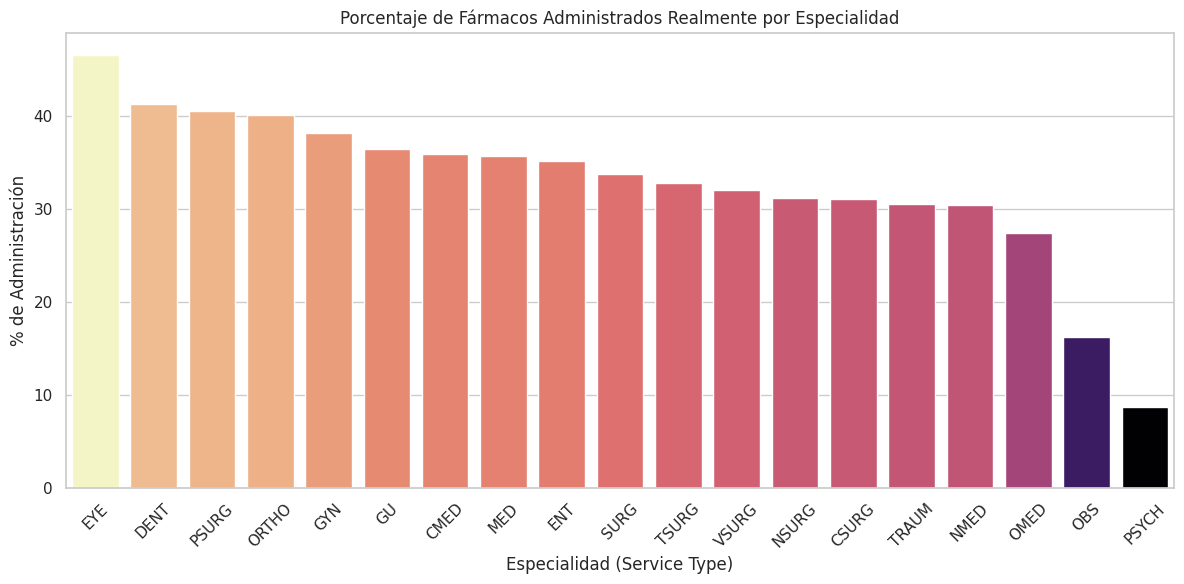

In [12]:
# ==============================================================================
# 3.1 TASA DE ADMINISTRACIÓN POR ESPECIALIDAD
# ==============================================================================
print("--- 7. AUDITORÍA: TASA DE ADMINISTRACIÓN POR ESPECIALIDAD ---")
tasa_admin_esp = df.groupby('service_type')['fue_administrado'].agg(
    total_recetas='count', administradas='sum'
).reset_index()

tasa_admin_esp['porcentaje_administrado'] = (tasa_admin_esp['administradas'] / tasa_admin_esp['total_recetas']) * 100
tasa_admin_esp = tasa_admin_esp.sort_values(by='porcentaje_administrado', ascending=False)

print(tasa_admin_esp.to_string(index=False))

# Gráfico visual para las especialidades
plt.figure(figsize=(12, 6))
sns.barplot(data=tasa_admin_esp, x='service_type', y='porcentaje_administrado', hue='porcentaje_administrado', palette='magma', legend=False)
plt.title('Porcentaje de Fármacos Administrados Realmente por Especialidad')
plt.xlabel('Especialidad (Service Type)')
plt.ylabel('% de Administración')
plt.xticks(rotation=45)
plt.show()

El modelo aprenderá en qué departamentos se administra más o menos medicación gracias a la bandera fue_administrado, que registra si la enfermería aplicó físicamente el fármaco en planta.

Así, la IA comprenderá que las altas tasas en hospitalización responden a tratamientos directos, mientras que los bajos porcentajes en áreas como Psiquiatría u Obstetricia se deben a pautas de alta domiciliaria. Esto dota al sistema de una base de normalidad para evitar falsos positivos y detectar anomalías con precisión.

## 3.2 Fármacos con mayor y menor tasa de administración

In [13]:
# ==============================================================================
# 3.2 FÁRMACOS CON MENOR Y MAYOR TASA DE ADMINISTRACIÓN
# ==============================================================================
print("--- 8. AUDITORÍA: FÁRMACOS CON MENOR Y MAYOR TASA DE ADMINISTRACIÓN ---")
tasa_med = df.groupby('medication').agg(
    total_recetas=('fue_administrado', 'count'),
    administradas=('fue_administrado', 'sum')
).reset_index()

tasa_med['porcentaje_administrado'] = (tasa_med['administradas'] / tasa_med['total_recetas']) * 100

# Filtramos fármacos con relevancia estadística (más de 100 recetas)
tasa_med_relevantes = tasa_med[tasa_med['total_recetas'] > 100]

print("Top 5 Fármacos con MAYOR tasa de administración:")
print(tasa_med_relevantes.sort_values(by='porcentaje_administrado', ascending=False).head(5).to_string(index=False))

print("\nTop 5 Fármacos con MENOR tasa de administración (Posibles cancelaciones/alertas):")
print(tasa_med_relevantes.sort_values(by='porcentaje_administrado', ascending=True).head(5).to_string(index=False))

--- 8. AUDITORÍA: FÁRMACOS CON MENOR Y MAYOR TASA DE ADMINISTRACIÓN ---
Top 5 Fármacos con MAYOR tasa de administración:
                                    medication  total_recetas  administradas  porcentaje_administrado
                                     rifAXIMin            143            134                93.706294
         Neostigmine (CVICU Reversal Protocol)            109            102                93.577982
                           Esomeprazole sodium            137            128                93.430657
IV Fluid / Mix: 2 g / 100 mL Dextrose (iso-os)           1296           1187                91.589506
                                 DULoxetine DR            146            133                91.095890

Top 5 Fármacos con MENOR tasa de administración (Posibles cancelaciones/alertas):
                          medication  total_recetas  administradas  porcentaje_administrado
                           Phenytoin            724              0                      0.0


El estudio detallado a nivel de fármaco identifica elementos con una tasa de administración intrahospitalaria nula (0,0 %), a pesar de contar con un volumen relevante de prescripciones (como analgésicos de liberación prolongada u optimizadores respiratorios).

 Este fenómeno se explica porque la bandera fue_administrado depende estrictamente de que la enfermería pinche o entregue el fármaco físicamente en la cama del hospital: los fármacos con menor probabilidad de marcarse como True suelen corresponder a recetas de alta para llevar a casa, inhaladores de uso personal (self-administration) o tratamientos condicionales (PRN o "según necesidad").

 Comprender que la probabilidad de que fue_administrado sea afirmativo depende directamente del tipo de medicamento permite que el modelo de aprendizaje automático aprenda las limitaciones operativas reales del entorno hospitalario y distinga con precisión entre una pauta domiciliaria legítima y una posible anomalía clínica.





# **BLOQUE 4: Análisis profundo de Médicos**

---





In [14]:
# ==============================================================================
# ASEGURAR COLUMNAS TEMPORALES EN EL DATAFRAME PRINCIPAL
# ==============================================================================
df['authored_on'] = pd.to_datetime(df['authored_on'], errors='coerce', utc=True)

# Creamos las columnas de semana y mes de forma global en 'df'
if 'semana' not in df.columns:
    df['semana'] = df['authored_on'].dt.to_period('W')

if 'mes' not in df.columns:
    df['mes'] = df['authored_on'].dt.to_period('M')

print("✅ Columnas temporales 'semana' y 'mes' creadas y listas para usar en todo el DataFrame.")

✅ Columnas temporales 'semana' y 'mes' creadas y listas para usar en todo el DataFrame.


## 4.1 Número de Médicos Activos durante el tiempo

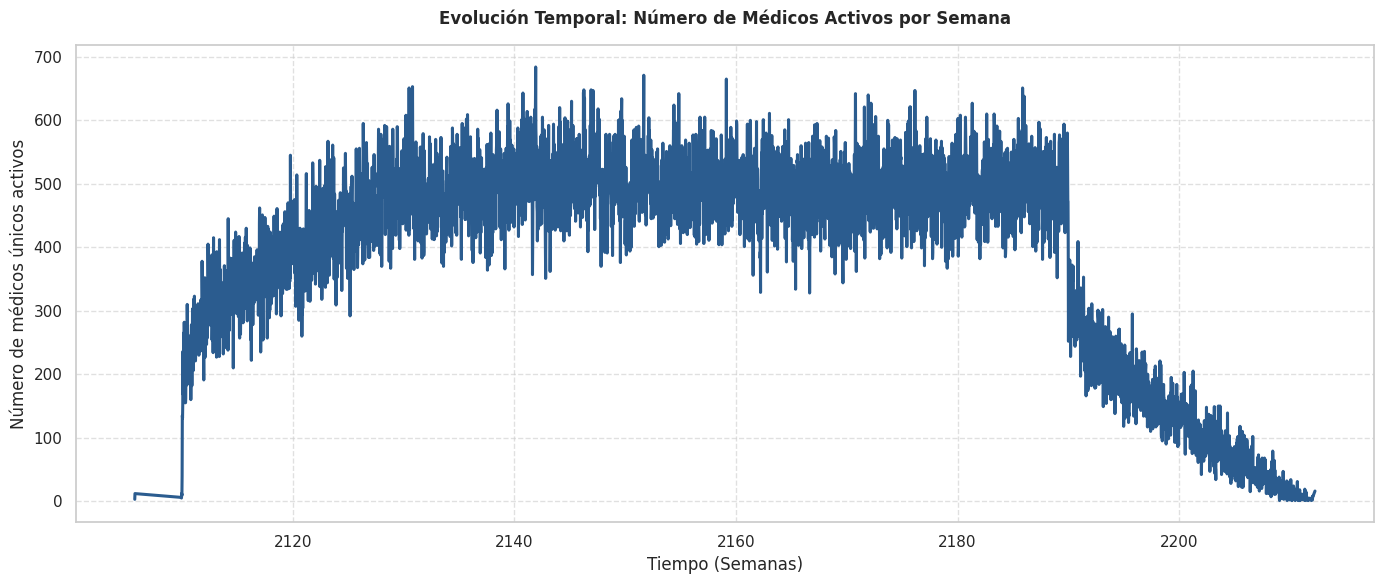

In [15]:
# ==============================================================================
# 4.1. EVOLUCIÓN TEMPORAL: Número Total de Médicos Activos por Semana
# ==============================================================================
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

# Asegurarnos de que la columna fecha y semana existen en el DataFrame principal
if 'authored_on' in df.columns and 'semana' not in df.columns:
    df['authored_on'] = pd.to_datetime(df['authored_on'], errors='coerce', utc=True)
    df['semana'] = df['authored_on'].dt.to_period('W')

# Agrupamos por semana para contar cuántos médicos únicos están activos
medicos_activos_semana = df.groupby('semana')['provider_id'].nunique().reset_index()
medicos_activos_semana['semana'] = medicos_activos_semana['semana'].dt.to_timestamp()

# Gráfica
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=medicos_activos_semana,
    x='semana',
    y='provider_id',
    color='#2b5c8f',
    linewidth=2.2
)
plt.title('Evolución Temporal: Número de Médicos Activos por Semana', weight='bold', pad=15)
plt.xlabel('Tiempo (Semanas)')
plt.ylabel('Número de médicos únicos activos')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## 4.2 Número de Pacientes diferentes que atienden los Médicos durante el tiempo

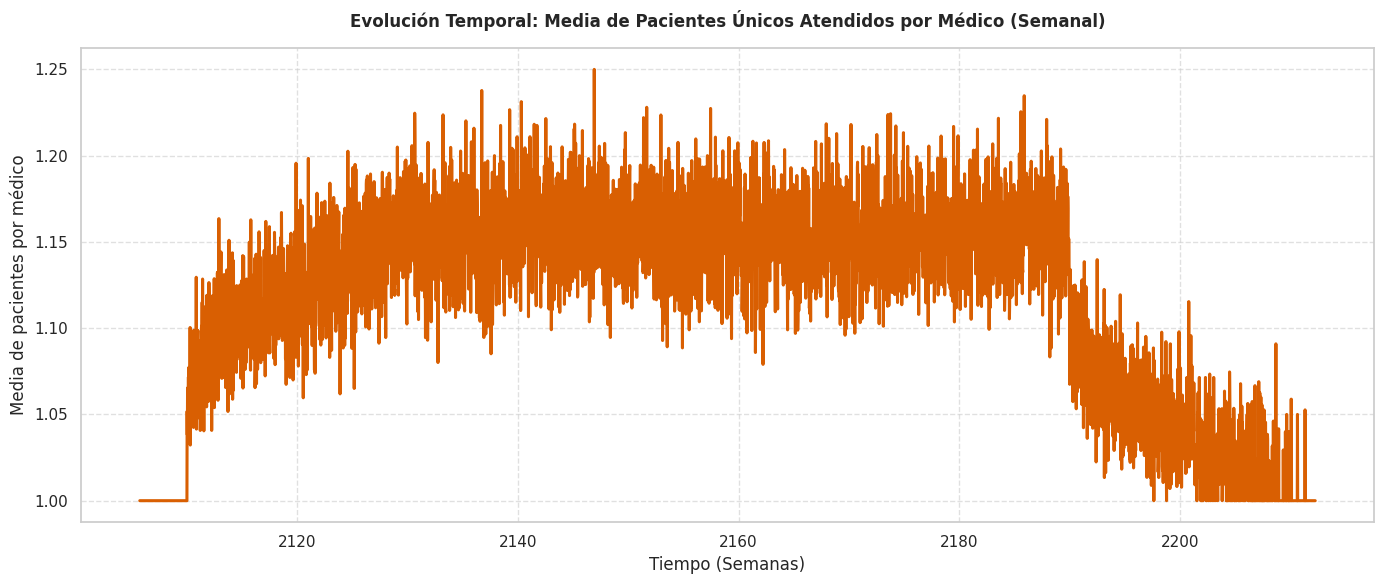

In [16]:
# ==============================================================================
# 4.2. EVOLUCIÓN TEMPORAL: Media de pacientes únicos atendidos por médico
# ==============================================================================
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

# Asegurarnos de que la columna fecha y semana existen en el DataFrame principal
if 'authored_on' in df.columns and 'semana' not in df.columns:
    df['authored_on'] = pd.to_datetime(df['authored_on'], errors='coerce', utc=True)
    df['semana'] = df['authored_on'].dt.to_period('W')

# Agrupamos por semana y médico para contar pacientes únicos por cada uno
pacientes_por_medico_semana = df.groupby(['semana', 'provider_id'])['patient_id'].nunique().reset_index()

# Calculamos la media global de pacientes por médico para cada semana
media_pac_medico_semana = pacientes_por_medico_semana.groupby('semana')['patient_id'].mean().reset_index()
media_pac_medico_semana['semana'] = media_pac_medico_semana['semana'].dt.to_timestamp()

# Gráfica
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=media_pac_medico_semana,
    x='semana',
    y='patient_id',
    color='#d95f02',
    linewidth=2.2
)
plt.title('Evolución Temporal: Media de Pacientes Únicos Atendidos por Médico (Semanal)', weight='bold', pad=15)
plt.xlabel('Tiempo (Semanas)')
plt.ylabel('Media de pacientes por médico')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

La evolución temporal de la media de pacientes únicos por médico muestra una estabilidad constante en torno a 1.1-1.2 pacientes por semana. Este valor, aparentemente bajo, responde al sesgo estructural de los registros hospitalarios a gran escala, donde un elevado volumen de profesionales sanitarios registra intervenciones puntuales o guardias asociadas a un único paciente por semana, situando la mediana en 1.0.

In [17]:
# Comprobamos cuántos pacientes únicos atiende un médico en una semana de forma general
pacientes_semana_temp = df.groupby(['semana', 'provider_id'])['patient_id'].nunique()
print(pacientes_semana_temp.describe())

count    2.092138e+06
mean     1.143500e+00
std      4.518495e-01
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.100000e+01
Name: patient_id, dtype: float64


El análisis estadístico de los registros confirma que la mediana y los percentiles 25, 50 y 75 se sitúan exactamente en 1,0, lo que evidencia que en más del 75% de las observaciones semanales un profesional atiende a un único paciente.

Este predominio masivo de registros con un solo paciente por semana explica por qué la media global se ancla firmemente en torno a 1,14, quedando los picos de mayor carga clínica (como el max en 11) diluidos frente a la gran cantidad de intervenciones puntuales o guardias puntuales en el sistema.

## 4.3 Análisis de la selección de 10 Médicos 'tipo'

### 4.3.1 Selección de los 10 médicos

In [19]:
# ==============================================================================
# 4.3.1. SELECCIÓN DE 5 MÉDICOS "TIPO" (Criterio equilibrado: activos, no outliers)
# ==============================================================================
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

# 1. Asegurar formato datetime y columnas temporales
df['authored_on'] = pd.to_datetime(df['authored_on'], errors='coerce', utc=True)
df['semana'] = df['authored_on'].dt.to_period('W')
df['mes'] = df['authored_on'].dt.to_period('M')

# 2. Calcular estadísticas completas por médico
stats_medicos = df.groupby('provider_id').agg(
    total_recetas=('medication', 'count'),
    semanas_activas=('semana', 'nunique'),
    meses_activos=('mes', 'nunique')
).reset_index()

# 3. FILTRO EQUILIBRADO: Entre 400 y 1.500 recetas y al menos 6 meses de vida activa
medicos_candidatos = stats_medicos[
    (stats_medicos['total_recetas'] >= 400) &
    (stats_medicos['total_recetas'] <= 1500) &
    (stats_medicos['meses_activos'] >= 6)
]

# 4. Seleccionar 5 médicos representativos de este rango óptimo
lista_5_medicos = medicos_candidatos.head(5)['provider_id'].tolist()

print(f"✅ Se han seleccionado {len(lista_5_medicos)} médicos 'tipo' equilibrados.")
print("IDs seleccionados:", lista_5_medicos)

# 5. Crear el DataFrame filtrado definitivo
df_5_medicos = df[df['provider_id'].isin(lista_5_medicos)].copy()

✅ Se han seleccionado 5 médicos 'tipo' equilibrados.
IDs seleccionados: ['P001ZX', 'P003V2', 'P004WO', 'P00503', 'P0056Y']


In [20]:
# ==============================================================================
# EXPLORACIÓN DE VOLÚMENES TOTALES POR MÉDICO
# ==============================================================================
print(stats_medicos['total_recetas'].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]))

count     7697.000000
mean       311.447707
std        604.807907
min          1.000000
50%         74.000000
75%        389.000000
90%       1015.400000
95%       1341.200000
99%       1870.160000
max      12595.000000
Name: total_recetas, dtype: float64


El análisis de los datos evidencia una distribución fuertemente sesgada: el 75% de los médicos registra menos de 389 prescripciones, mientras que unos pocos valores atípicos alcanzan un máximo de 12.595, situando la mediana en un nivel bajo (74 recetas).

### 4.3.2 Número de Pacientes diferentes vs nuevos

Número de pacientes diferentes con los que trata sobre el tiempo, y número de pacientes que son nuevos

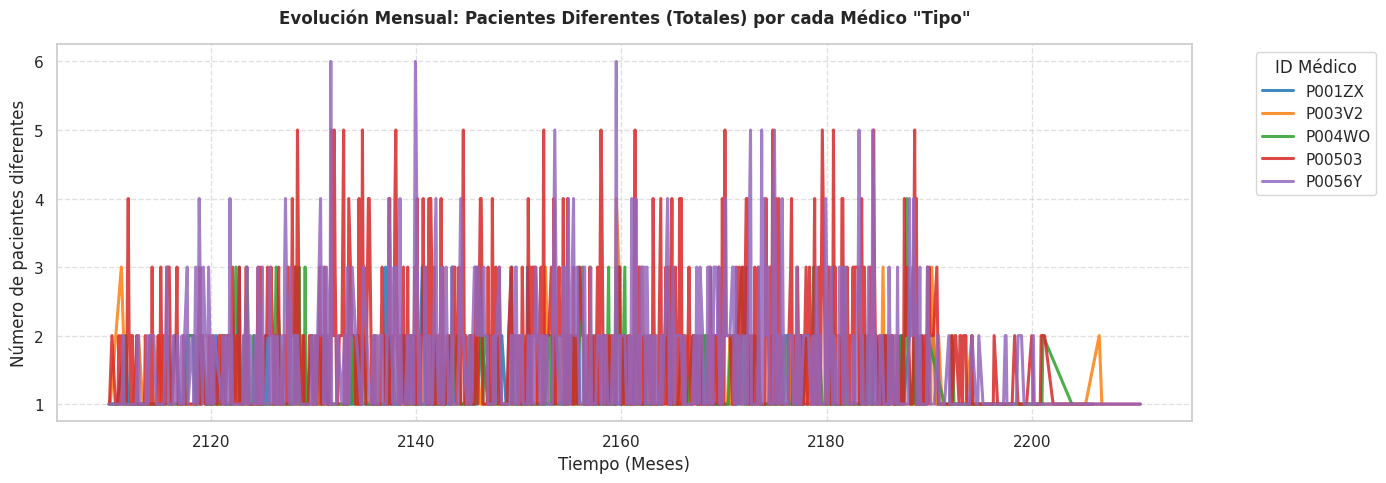

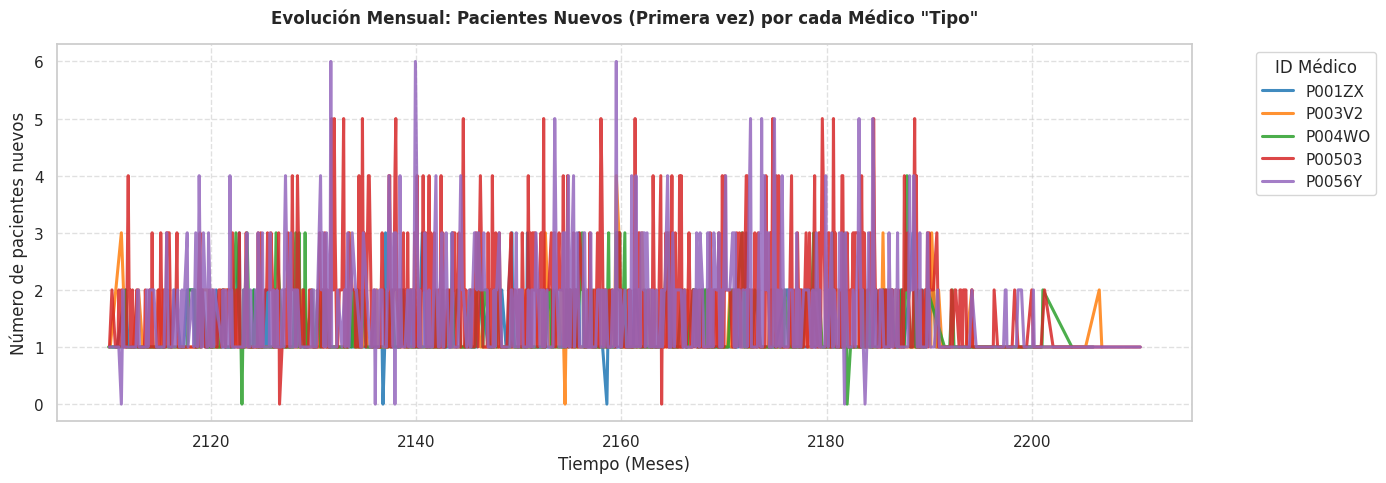

In [21]:
# ==============================================================================
# 4.3.2. PACIENTES: Gráficas Separadas para Totales y Nuevos (5 perfiles individuales)
# ==============================================================================
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

# 1. Preparar el DataFrame base para los 5 médicos
df_5 = df_5_medicos.copy()
df_5 = df_5.sort_values(by=['provider_id', 'authored_on'])
df_5['mes'] = df_5['authored_on'].dt.to_period('M')

# 2. Identificar si es la primera vez absoluta que el médico atiende a este paciente
df_5['es_nuevo'] = ~df_5.duplicated(subset=['provider_id', 'patient_id'], keep='first')

# 3. Agrupar por médico y mes calculando ambas métricas
res_pacs = []
for m_id, grp in df_5.groupby('provider_id'):
    p_mes = grp.groupby('mes').agg(
        total_pacientes=('patient_id', 'nunique'),
        pacientes_nuevos=('es_nuevo', lambda x: grp.loc[x.index, 'patient_id'][x].nunique())
    ).reset_index()
    p_mes['provider_id'] = m_id
    res_pacs.append(p_mes)

df_pacs_total = pd.concat(res_pacs)
df_pacs_total['mes_ts'] = df_pacs_total['mes'].dt.to_timestamp()

# ==============================================================================
# GRÁFICA 1: Pacientes Diferentes (Totales en el mes) por Médico Individual
# ==============================================================================
plt.figure(figsize=(14, 5))
sns.lineplot(
    data=df_pacs_total,
    x='mes_ts',
    y='total_pacientes',
    hue='provider_id',
    palette='tab10',
    linewidth=2.2,
    alpha=0.85
)
plt.title('Evolución Mensual: Pacientes Diferentes (Totales) por cada Médico "Tipo"', weight='bold', pad=15)
plt.xlabel('Tiempo (Meses)')
plt.ylabel('Número de pacientes diferentes')
plt.legend(title='ID Médico', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# ==============================================================================
# GRÁFICA 2: Pacientes Nuevos (Primera vez absoluta) por Médico Individual
# ==============================================================================
plt.figure(figsize=(14, 5))
sns.lineplot(
    data=df_pacs_total,
    x='mes_ts',
    y='pacientes_nuevos',
    hue='provider_id',
    palette='tab10',
    linewidth=2.2,
    alpha=0.85
)
plt.title('Evolución Mensual: Pacientes Nuevos (Primera vez) por cada Médico "Tipo"', weight='bold', pad=15)
plt.xlabel('Tiempo (Meses)')
plt.ylabel('Número de pacientes nuevos')
plt.legend(title='ID Médico', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

El análisis comparativo entre pacientes únicos totales y pacientes nuevos revela una superposición casi total en las curvas mensuales. Esto evidencia que la actividad de estos médicos 'tipo' se basa en una rotación constante de pacientes nuevos más que en un seguimiento longitudinal de pacientes crónicos recurrentes.

## 4.3.3 Número de medicamentos prescritos a lo largo del tiempo

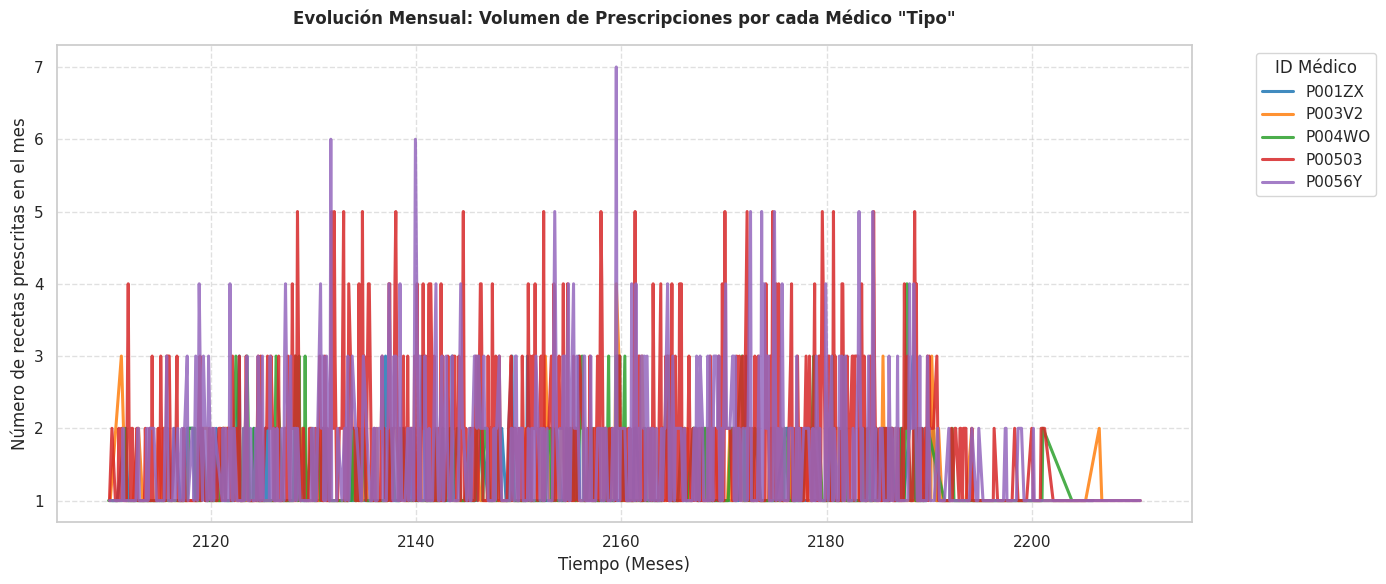

In [22]:
# ==============================================================================
# 4.3.3. MEDICAMENTOS: Evolución Individual del Volumen de Prescripciones
# ==============================================================================
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

# Agrupamos por cada médico y mes para contar sus recetas individuales
meds_tiempo = df_5_medicos.groupby(['provider_id', 'mes']).size().reset_index(name='num_medicamentos')
meds_tiempo['mes_ts'] = meds_tiempo['mes'].dt.to_timestamp()

# Gráfica individual para cada uno de los 5 médicos
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=meds_tiempo,
    x='mes_ts',
    y='num_medicamentos',
    hue='provider_id',
    palette='tab10',
    linewidth=2.2,
    alpha=0.85
)
plt.title('Evolución Mensual: Volumen de Prescripciones por cada Médico "Tipo"', weight='bold', pad=15)
plt.xlabel('Tiempo (Meses)')
plt.ylabel('Número de recetas prescritas en el mes')
plt.legend(title='ID Médico', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

A pesar de cumplir con un volumen total acumulado moderado, la distribución temporal revela que la actividad mensual por médico se mantiene en un rango acotado (de 1 a 7 recetas por mes), lo que evidencia una interacción intermitente o de baja frecuencia mensual con el sistema a lo largo del periodo analizado.

## 4.3.4 Media de Medicamentos Diferentes por Paciente (IC 95%)

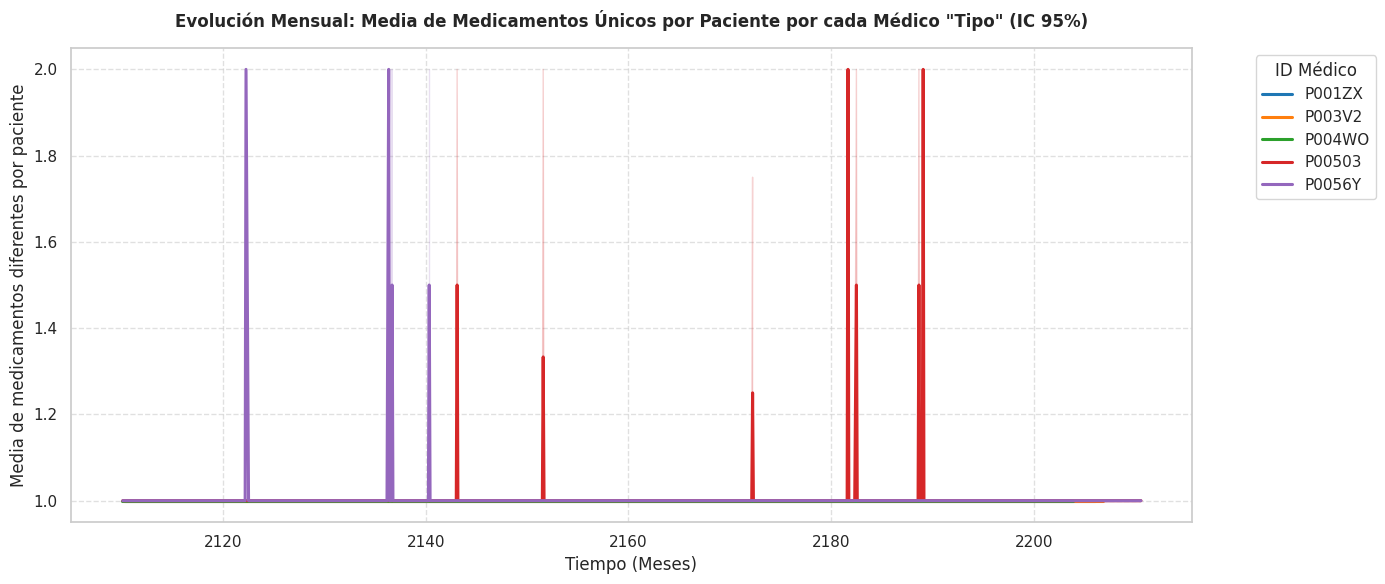

In [23]:
# ==============================================================================
# 4.3.4. POLIMEDICACIÓN: Media de Medicamentos Diferentes por Paciente
# ==============================================================================
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

# 1. Agrupamos por médico, mes y paciente usando el DataFrame de los 5 médicos
meds_por_paciente = df_5_medicos.groupby(['provider_id', 'mes', 'patient_id'])['medication'].nunique().reset_index(name='num_meds_unicos')
meds_por_paciente['mes_ts'] = meds_por_paciente['mes'].dt.to_timestamp()

# 2. Gráfica con líneas individuales y bandas de intervalo de confianza (IC 95%) para cada médico
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=meds_por_paciente,
    x='mes_ts',
    y='num_meds_unicos',
    hue='provider_id',       # Una línea y color independiente para cada uno de los 5 médicos
    palette='tab10',
    linewidth=2.2,
    errorbar=('ci', 95)      # Intervalo de confianza del 95% sombreado por médico
)
plt.title('Evolución Mensual: Media de Medicamentos Únicos por Paciente por cada Médico "Tipo" (IC 95%)', weight='bold', pad=15)
plt.xlabel('Tiempo (Meses)')
plt.ylabel('Media de medicamentos diferentes por paciente')
plt.legend(title='ID Médico', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Los resultados se mantienen estables y anclados de forma constante en el valor mínimo de 1,0 durante la mayor parte del tiempo, con puntuales picos aislados que alcanzan valores entre 1,5 y 2,0. Esto indica que estos profesionales recetan sistemáticamente un único fármaco por paciente en sus interacciones mensuales, reflejando una baja complejidad o una prescripción muy focalizada en este subgrupo analizado

## 4.3.5 Media de Medicamentos Prescritos por Encuentro Clínico (IC 95%)

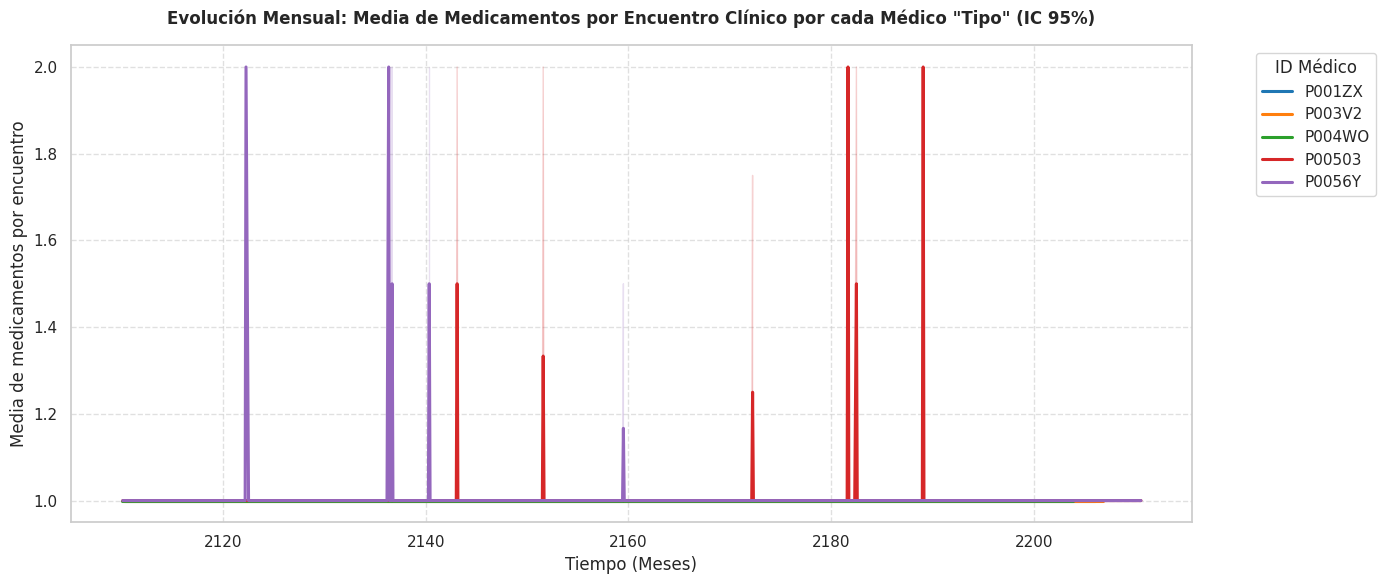

In [26]:
# ==============================================================================
# 4.3.5. ENCUENTROS: Media de Medicamentos por Encuentro Clínico (5 perfiles)
# ==============================================================================
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

# 1. Agrupamos por médico, mes y encuentro usando el DataFrame de los 5 médicos
meds_por_encuentro = df_5_medicos.groupby(['provider_id', 'mes', 'encounter_id'])['medication'].count().reset_index(name='num_meds_encuentro')
meds_por_encuentro['mes_ts'] = meds_por_encuentro['mes'].dt.to_timestamp()

# 2. Gráfica individual con líneas y bandas de intervalo de confianza (IC 95%) para cada médico
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=meds_por_encuentro,
    x='mes_ts',
    y='num_meds_encuentro',
    hue='provider_id',       # Una línea y color independiente para cada uno de los 5 médicos
    palette='tab10',
    linewidth=2.2,
    errorbar=('ci', 95)      # Intervalo de confianza del 95% sombreado por médico
)
plt.title('Evolución Mensual: Media de Medicamentos por Encuentro Clínico por cada Médico "Tipo" (IC 95%)', weight='bold', pad=15)
plt.xlabel('Tiempo (Meses)')
plt.ylabel('Media de medicamentos por encuentro')
plt.legend(title='ID Médico', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Al igual que en el caso anterior, los valores se mantienen de forma constante y uniforme en el mínimo de 1,0 a lo largo del tiempo, con picos esporádicos y aislados que alcanzan valores de entre 1,5 y 2,0. Esto indica que por cada encuentro o visita clínica registrada, estos profesionales emiten de forma sistemática una única prescripción farmacéutica, evidenciando un patrón asistencial homogéneo y de baja intensidad en términos de polimedicación por consulta.

## 4.4.6 Mapa de Calor por Hora y Día de la Semana sobre la prescripción de medicamentos

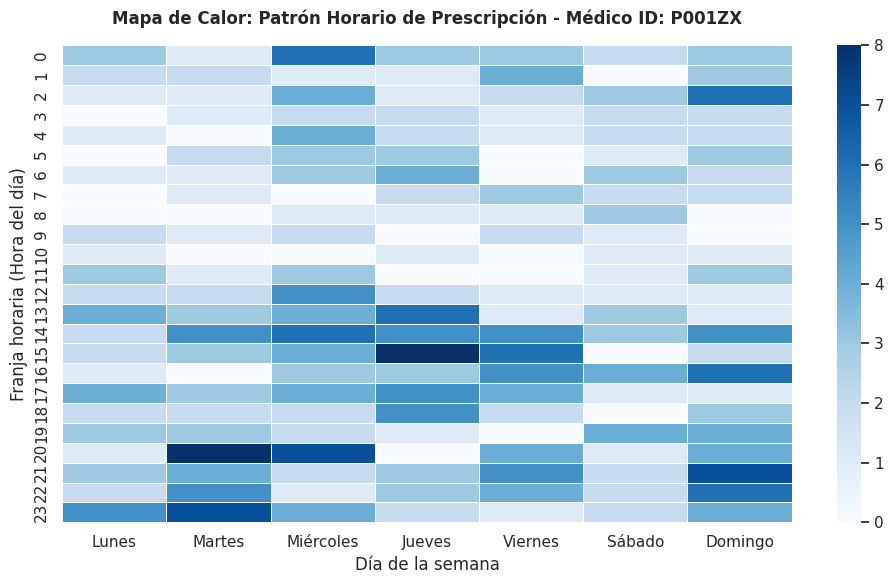

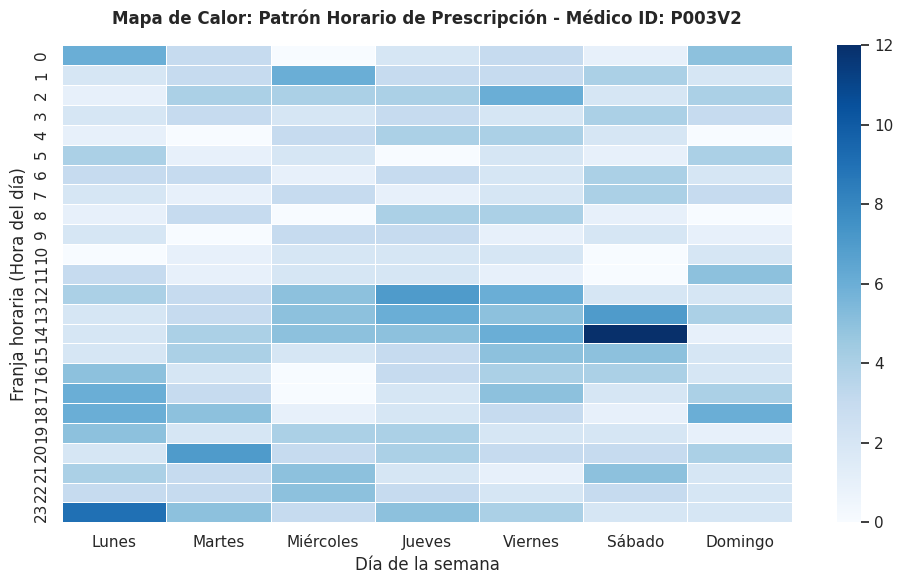

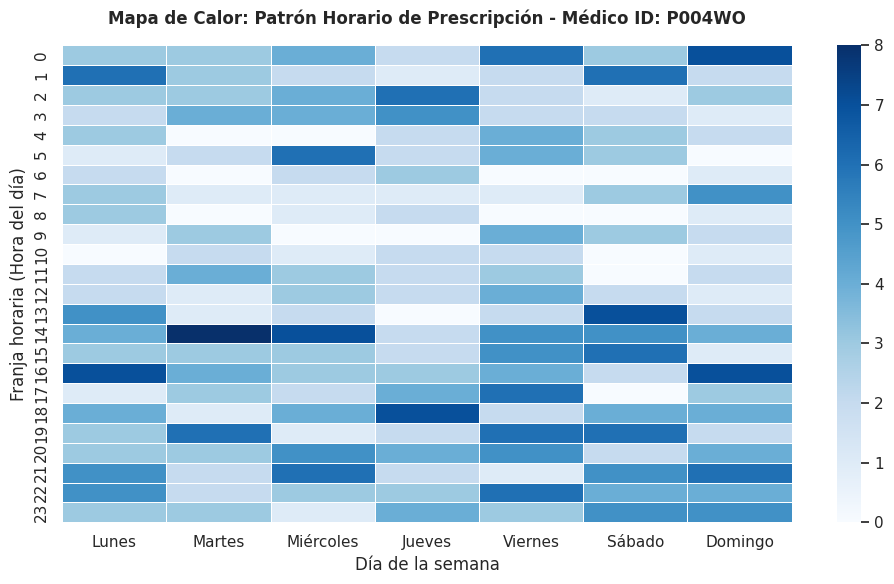

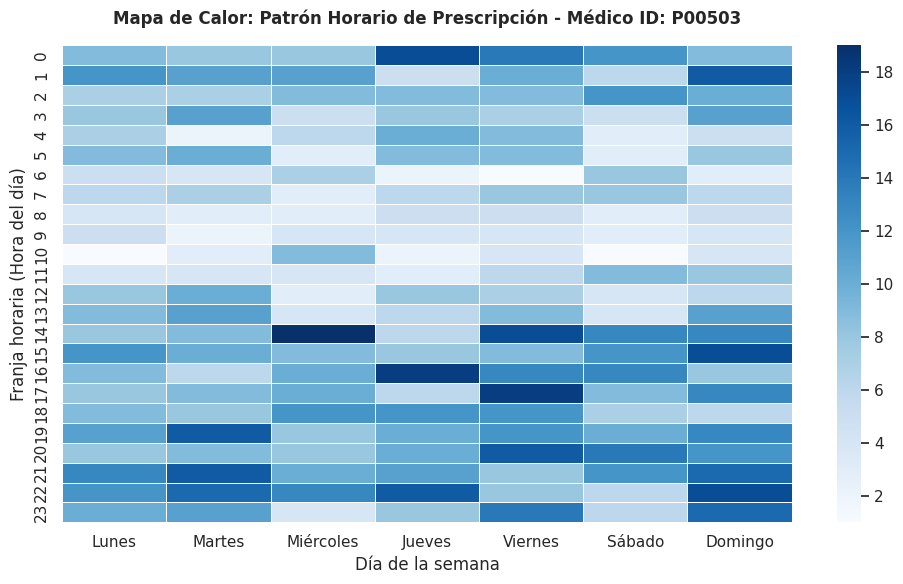

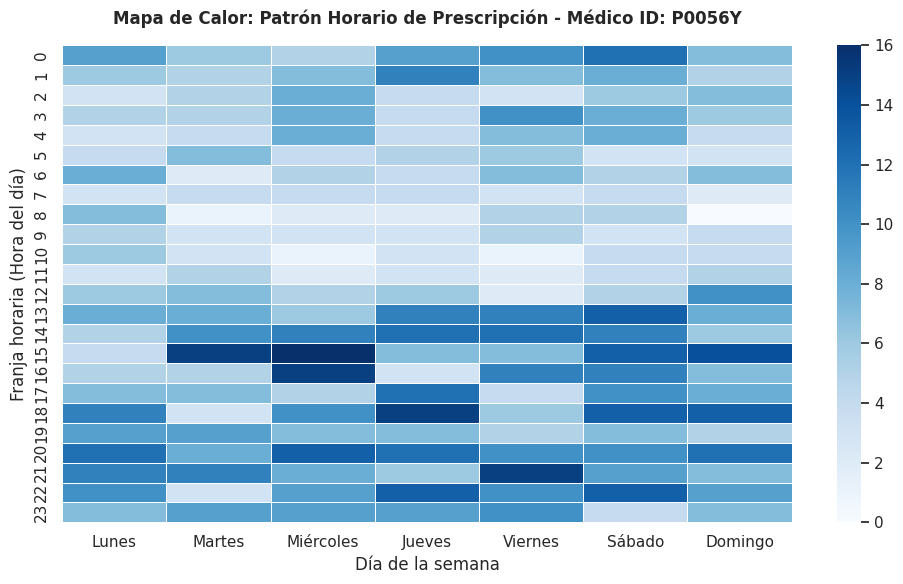

In [25]:
# ==============================================================================
# 4.4.6. MAPAS DE CALOR INDIVIDUALES: Patrón Horario por Médico "Tipo"
# ==============================================================================
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

dias_orden = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dias_es = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']

# Iteramos por cada médico de la lista de los 5
for med_id in lista_5_medicos:
    # Filtramos los datos de este médico en concreto
    df_med = df_5_medicos[df_5_medicos['provider_id'] == med_id].copy()

    df_med['dia_semana'] = df_med['authored_on'].dt.day_name()
    df_med['hora'] = df_med['authored_on'].dt.hour

    # Tabla cruzada de horas vs días para este médico
    heatmap_data = pd.crosstab(index=df_med['hora'], columns=df_med['dia_semana'])
    heatmap_data = heatmap_data.reindex(columns=[d for d in dias_orden if d in heatmap_data.columns])
    heatmap_data.columns = [dias_es[dias_orden.index(d)] for d in heatmap_data.columns]

    # Dibujamos una gráfica para cada médico
    plt.figure(figsize=(10, 6))
    sns.heatmap(heatmap_data, cmap='Blues', annot=False, fmt='d', cbar=True, linewidths=.5)
    plt.title(f'Mapa de Calor: Patrón Horario de Prescripción - Médico ID: {med_id}', weight='bold', pad=15)
    plt.xlabel('Día de la semana')
    plt.ylabel('Franja horaria (Hora del día)')
    plt.show()